# 02 — Analysis

Owner: Dat (Q1, Q3) + Khoi (Q4). Data loaded from `data/processed/` (see ADR-003).

Authority order: `ADR > SPECIFICATION.md > notebook`.

In [1]:
# Setup — imports, paths, constants
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
from scipy.stats import ConstantInputWarning
warnings.filterwarnings("ignore", category=ConstantInputWarning)

# Repo root on sys.path so we can reuse prepare_data.py constants
ROOT = Path("..").resolve() if not Path("data").exists() else Path(".").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from prepare_data import EDGAR_COUNTRY_MAP, SECTOR_GROUP, TARGET_COUNTRIES

DATA = ROOT / "data"
PROCESSED = DATA / "processed"

SEED = 20261123
RNG = np.random.default_rng(SEED)

COUNTRY_ISO3 = {
    "Vietnam": "VNM", "Thailand": "THA", "Singapore": "SGP",
    "China": "CHN", "Japan": "JPN", "Germany": "DEU",
    "United States": "USA", "New Zealand": "NZL",
}

SPEARMAN_CRIT = 0.7857  # displayed as 0.786 (SPECIFICATION S5)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print("Setup OK — data dir:", DATA.resolve())


Setup OK — data dir: /home/datle/programming-for-ds/csc17104-ev-adoption-grid/data


## Q1 — Transport share vs adoption pace (Dat)

**Question (ADR-001, SPECIFICATION S1):** Does the transport weight in national CO2 predict the pace of electrification, after controlling for income?

**Hypothesis H1 (directional):** higher transport share goes with faster adoption. If the sign is opposite or indistinguishable from 0, report as-is (no causal language).

**Sample:** 7 countries (Singapore excluded — no IEA rows). Transport share from EDGAR 2025 (structure described for all 8).

**Decision rule (SPECIFICATION S5):** |rho| >= 0.786 (exact 0.7857, alpha=0.05 two-sided, 5,040 permutations) **and** bootstrap 95% CI excludes 0. With n=7, a null result is **not** evidence of no relationship.

**Depth criteria:** D1 (three-source merge), D2 (period-over-period change), D3 (transport CO2 per capita, adoption pace), D4 (income control), D5 (bootstrap CI), D6 (year & series robustness).


In [2]:
# --- Load processed CSVs (ADR-003) ---
emissions = pd.read_csv(PROCESSED / "emissions_long.csv")
ev = pd.read_csv(PROCESSED / "ev_long.csv")

print("emissions_long:", emissions.shape, "rows,", emissions["country"].nunique(), "countries")
print("ev_long:", ev.shape, "rows,", ev["country"].nunique(), "countries")
assert emissions.shape[0] == 61, f"expected 61 emissions rows, got {len(emissions)}"
assert ev.shape[0] == 496, f"expected 496 ev rows, got {len(ev)}"

print("EDGAR years:", sorted(emissions["year"].unique()))
print("EV years:", int(ev["year"].min()), "to", int(ev["year"].max()))
print("EV parameters:", sorted(ev["parameter"].unique()))
assert set(ev["parameter"].unique()) == {"EV sales share", "EV stock share", "EV charging points"}


emissions_long: (61, 6) rows, 8 countries
ev_long: (496, 7) rows, 7 countries
EDGAR years: [2025]
EV years: 2010 to 2024
EV parameters: ['EV charging points', 'EV sales share', 'EV stock share']


In [3]:
# --- EDGAR 2025: transport & sector shares per country ---
co2 = emissions[(emissions["substance"] == "CO2") & (emissions["year"] == 2025)].copy()

totals = co2.groupby("country")["emissions_mt"].sum().rename("total_mt")
transport = co2[co2["sector"] == "Transport"].set_index("country")["emissions_mt"].rename("transport_mt")

sector_pivot = co2.pivot_table(index="country", columns="sector_group",
                               values="emissions_mt", aggfunc="sum", fill_value=0)
sector_shares = sector_pivot.div(sector_pivot.sum(axis=1), axis=0) * 100

q1 = pd.DataFrame({"transport_mt": transport, "total_mt": totals})
for col in ["Transport", "Industry", "Power", "Other"]:
    if col in sector_shares.columns:
        q1[f"{col.lower()}_share"] = sector_shares[col]

q1 = q1.sort_index()
print("Transport share of national CO2, 2025 (8 countries):")
display(q1.round(2))


Transport share of national CO2, 2025 (8 countries):


,transport_mt,total_mt,transport_share,industry_share,power_share,other_share
country,,,,,,
China,1088.25,13057.11,8.33,30.74,50.28,10.64
Germany,136.87,567.76,24.11,20.42,31.43,24.04
Japan,179.84,977.28,18.40,21.57,44.89,15.14
New Zealand,15.38,29.16,52.73,21.22,11.91,14.13
Singapore,5.73,57.14,10.02,41.68,39.50,8.81
Thailand,81.00,266.94,30.34,27.27,30.59,11.80
United States,1724.64,4739.09,36.39,12.96,33.03,17.63
Vietnam,50.81,386.97,13.13,35.57,46.04,5.26


In [4]:
# --- IEA: adoption pace (cars, 2018 -> 2024) ---
ev_sales = ev[(ev["parameter"] == "EV sales share") & (ev["mode"] == "Cars")
              & (ev["powertrain"] == "EV")].copy()

level_2018 = ev_sales[ev_sales["year"] == 2018].set_index("country")["value"].rename("ev_share_2018")
level_2024 = ev_sales[ev_sales["year"] == 2024].set_index("country")["value"].rename("ev_share_2024")

pace = pd.DataFrame({"ev_share_2018": level_2018, "ev_share_2024": level_2024})
pace["pace_pp"] = pace["ev_share_2024"] - pace["ev_share_2018"]

print("EV sales share (cars), 2018 vs 2024, and pace (pp):")
display(pace.round(4))

edgar_countries = set(q1.index)
iea_countries = set(pace.index)
print(f"\nEDGAR countries: {sorted(edgar_countries)}")
print(f"IEA countries (cars, 2018 & 2024): {sorted(iea_countries)}")
print(f"Excluded (no IEA data): {sorted(edgar_countries - iea_countries)}")
print(f"Unmatched IEA -> EDGAR: {sorted(iea_countries - edgar_countries)}")


EV sales share (cars), 2018 vs 2024, and pace (pp):


,ev_share_2018,ev_share_2024,pace_pp
country,,,
China,4.7000,48.0,43.3000
Germany,2.0000,19.0,17.0000
Japan,1.1000,2.8,1.7000
New Zealand,4.9000,11.0,6.1000
Thailand,0.8700,13.0,12.1300
United States,2.3000,10.0,7.7000
Vietnam,0.0016,17.0,16.9984



EDGAR countries: ['China', 'Germany', 'Japan', 'New Zealand', 'Singapore', 'Thailand', 'United States', 'Vietnam']
IEA countries (cars, 2018 & 2024): ['China', 'Germany', 'Japan', 'New Zealand', 'Thailand', 'United States', 'Vietnam']
Excluded (no IEA data): ['Singapore']
Unmatched IEA -> EDGAR: []


In [5]:
# --- World Bank Open Data: GDP per capita, population, income group ---
# Source: https://data.worldbank.org/ ; CC BY 4.0; accessed at runtime.
# Indicators: NY.GDP.PCAP.CD (GDP per capita), SP.POP.TOTL (population),
# incomeLevel (country endpoint). Cache to data/processed/ for reproducibility.
WB_CACHE = PROCESSED / "world_bank_q1.json"
ACCESS_DATE = "2026-11-24"

def fetch_wb():
    iso_list = ";".join(COUNTRY_ISO3.values())
    gdp_url = (f"https://api.worldbank.org/v2/country/{iso_list}/indicator/NY.GDP.PCAP.CD"
               f"?format=json&date=2010:2024&per_page=1000")
    pop_url = (f"https://api.worldbank.org/v2/country/{iso_list}/indicator/SP.POP.TOTL"
               f"?format=json&date=2010:2024&per_page=1000")
    country_url = f"https://api.worldbank.org/v2/country/{iso_list}?format=json&per_page=1000"

    gdp_resp = requests.get(gdp_url, timeout=30).json()
    pop_resp = requests.get(pop_url, timeout=30).json()
    country_resp = requests.get(country_url, timeout=30).json()

    records = {
        "gdp": gdp_resp[1],
        "pop": pop_resp[1],
        "country": country_resp[1],
        "access_date": ACCESS_DATE,
        "last_updated": gdp_resp[0].get("lastupdated"),
    }
    with open(WB_CACHE, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)
    print(f"Cached World Bank data to {WB_CACHE}")
    return records

if WB_CACHE.exists():
    with open(WB_CACHE, encoding="utf-8") as f:
        wb = json.load(f)
    print(f"Loaded cached World Bank data from {WB_CACHE}")
else:
    wb = fetch_wb()

# Parse GDP per capita (2010-2024)
gdp_map = {}
for r in wb["gdp"]:
    iso3 = r["countryiso3code"]
    year = r["date"]
    val = r["value"]
    if val is not None:
        gdp_map.setdefault(iso3, {})[year] = val

# Parse population (2010-2024)
pop_map = {}
for r in wb["pop"]:
    iso3 = r["countryiso3code"]
    year = r["date"]
    val = r["value"]
    if val is not None:
        pop_map.setdefault(iso3, {})[year] = val

# Parse income group
income_map = {}
for c in wb["country"]:
    income_map[c["id"]] = c["incomeLevel"]["value"]

# Build country-level summary (2024 values, for Q1)
wb_df = pd.DataFrame({"iso3": pd.Series(COUNTRY_ISO3)})
wb_df["gdp_2018"] = wb_df["iso3"].map(lambda x: gdp_map.get(x, {}).get("2018"))
wb_df["gdp_2024"] = wb_df["iso3"].map(lambda x: gdp_map.get(x, {}).get("2024"))
wb_df["pop_2024"] = wb_df["iso3"].map(lambda x: pop_map.get(x, {}).get("2024"))
wb_df["income_group"] = wb_df["iso3"].map(income_map)
wb_df.index.name = "country"

# Build long table (country, year) for year-specific GDP and population
wb_rows = []
for country_name, iso3 in COUNTRY_ISO3.items():
    gdp_by_year = gdp_map.get(iso3, {})
    pop_by_year = pop_map.get(iso3, {})
    for yr, gdp_val in gdp_by_year.items():
        wb_rows.append({
            "country": country_name,
            "year": int(yr),
            "gdp_pc": gdp_val,
            "pop": pop_by_year.get(yr),
            "income_group": income_map.get(iso3),
        })
wb_long = pd.DataFrame(wb_rows)
# Population: forward/backward fill within country for missing years
wb_long["pop"] = wb_long.groupby("country")["pop"].ffill().bfill()
wb_long["log_gdp"] = np.log(wb_long["gdp_pc"])

print(f"\nWorld Bank: access {wb['access_date']}, API lastupdated {wb.get('last_updated')}")
print(f"GDP years available: {sorted(set(r['date'] for r in wb['gdp']))}")
print(f"Population years available: {sorted(set(r['date'] for r in wb['pop']))}")
print("World Bank controls (2024):")
display(wb_df.round(0))


Loaded cached World Bank data from /home/datle/programming-for-ds/csc17104-ev-adoption-grid/data/processed/world_bank_q1.json

World Bank: access 2026-11-24, API lastupdated 2026-11-11
GDP years available: ['2018', '2019', '2020', '2021', '2022', '2023', '2024']
Population years available: ['2024']
World Bank controls (2024):


,iso3,gdp_2018,gdp_2024,pop_2024,income_group
country,,,,,
Vietnam,VNM,3222.0,4717.0,100987686,Upper middle income
Thailand,THA,7100.0,7387.0,71668011,Upper middle income
Singapore,SGP,67033.0,94897.0,6036860,High income
China,CHN,10086.0,13293.0,1408975000,Upper middle income
Japan,JPN,40645.0,33797.0,123975371,High income
Germany,DEU,48916.0,56104.0,83516593,High income
United States,USA,62876.0,86170.0,340003797,High income
New Zealand,NZL,43204.0,49432.0,5290000,High income


In [6]:
# --- Merge: EDGAR (8) x IEA (7) x World Bank (8) -> 7 ---
q1_full = q1.join(pace, how="inner")
q1_full = q1_full.join(wb_df[["gdp_2018", "gdp_2024", "pop_2024", "income_group"]], how="inner")

# Derived variables
q1_full["transport_t_per_capita"] = q1_full["transport_mt"] * 1e6 / q1_full["pop_2024"]
q1_full["log_gdp_2018"] = np.log(q1_full["gdp_2018"])
q1_full["log_gdp_2024"] = np.log(q1_full["gdp_2024"])

# Merge audit
edgar_set = set(q1.index)
iea_set = set(pace.index)
wb_set = set(wb_df.index)
merged_set = set(q1_full.index)

print("=== Merge audit ===")
print(f"EDGAR countries (transport share): {len(edgar_set)} -> {sorted(edgar_set)}")
print(f"IEA countries (cars, 2018 & 2024): {len(iea_set)} -> {sorted(iea_set)}")
print(f"World Bank countries: {len(wb_set)} -> {sorted(wb_set)}")
print(f"Merged (analysis sample): {len(merged_set)} -> {sorted(merged_set)}")
print(f"EDGAR - IEA (excluded by design): {sorted(edgar_set - iea_set)}")
print(f"IEA - EDGAR (unexpected): {sorted(iea_set - edgar_set)}")
print(f"WB - merged (unexpected): {sorted(wb_set - merged_set)}")

assert len(merged_set) == 7, f"expected 7, got {len(merged_set)}"
assert edgar_set - iea_set == {"Singapore"}, "unexpected EDGAR-IEA mismatch"
assert iea_set - edgar_set == set(), "unexpected IEA-EDGAR mismatch"
assert merged_set == iea_set, "merge dropped an IEA country"

print("\nQ1 analysis table:")
display_cols = ["transport_share", "industry_share", "power_share", "other_share",
                "transport_mt", "transport_t_per_capita",
                "ev_share_2018", "ev_share_2024", "pace_pp",
                "gdp_2024", "income_group"]
display(q1_full[display_cols].round(3))


=== Merge audit ===
EDGAR countries (transport share): 8 -> ['China', 'Germany', 'Japan', 'New Zealand', 'Singapore', 'Thailand', 'United States', 'Vietnam']
IEA countries (cars, 2018 & 2024): 7 -> ['China', 'Germany', 'Japan', 'New Zealand', 'Thailand', 'United States', 'Vietnam']
World Bank countries: 8 -> ['China', 'Germany', 'Japan', 'New Zealand', 'Singapore', 'Thailand', 'United States', 'Vietnam']
Merged (analysis sample): 7 -> ['China', 'Germany', 'Japan', 'New Zealand', 'Thailand', 'United States', 'Vietnam']
EDGAR - IEA (excluded by design): ['Singapore']
IEA - EDGAR (unexpected): []
WB - merged (unexpected): ['Singapore']

Q1 analysis table:


,transport_share,industry_share,power_share,other_share,transport_mt,transport_t_per_capita,ev_share_2018,ev_share_2024,pace_pp,gdp_2024,income_group
country,,,,,,,,,,,
China,8.335,30.741,50.279,10.645,1088.255,0.772,4.700,48.0,43.300,13293.116,Upper middle income
Germany,24.108,20.424,31.426,24.043,136.874,1.639,2.000,19.0,17.000,56103.732,High income
Japan,18.402,21.569,44.892,15.137,179.838,1.451,1.100,2.8,1.700,33797.101,High income
New Zealand,52.733,21.224,11.912,14.132,15.379,2.907,4.900,11.0,6.100,49432.363,High income
Thailand,30.344,27.267,30.589,11.800,81.001,1.130,0.870,13.0,12.130,7386.636,Upper middle income
United States,36.392,12.957,33.025,17.626,1724.636,5.072,2.300,10.0,7.700,86169.664,High income
Vietnam,13.131,35.565,46.041,5.263,50.812,0.503,0.002,17.0,16.998,4716.660,Upper middle income


In [7]:
# --- Primary analysis: Spearman rank correlation ---
x = q1_full["transport_share"].values
y = q1_full["pace_pp"].values
n = len(x)

rho, p_asym = stats.spearmanr(x, y)
print(f"Spearman rho = {rho:.4f}, asymptotic p = {p_asym:.4f}, n = {n}")

# Exact permutation p-value (5,040 permutations for n=7)
from itertools import permutations
observed_abs = abs(rho)
count = 0
total = 0
for perm in permutations(range(n)):
    r, _ = stats.spearmanr(x, y[list(perm)])
    total += 1
    if abs(r) >= observed_abs - 1e-12:
        count += 1
p_exact = count / total
print(f"Exact permutation p (two-sided, {total} reps) = {p_exact:.4f}")

# Bootstrap 95% CI (10,000 resamples)
rhos = []
for _ in range(10000):
    idx = RNG.integers(0, n, size=n)
    r, _ = stats.spearmanr(x[idx], y[idx])
    rhos.append(r)
rhos = np.array(rhos)
ci_lo, ci_hi = np.percentile(rhos, [2.5, 97.5])
print(f"Bootstrap 95% CI (10,000 resamples): [{ci_lo:.4f}, {ci_hi:.4f}]")
print(f"Bootstrap mean rho: {rhos.mean():.4f}, std: {rhos.std():.4f}")

# Decision rule
meets_threshold = abs(rho) >= SPEARMAN_CRIT
ci_excludes_zero = (ci_lo > 0) or (ci_hi < 0)
print(f"\n=== Decision rule (SPECIFICATION S5) ===")
print(f"|rho| = {abs(rho):.4f} >= {SPEARMAN_CRIT:.4f} (0.786)? {meets_threshold}")
print(f"Bootstrap CI excludes 0? {ci_excludes_zero}")
print(f"Decision: {'MEETS threshold' if (meets_threshold and ci_excludes_zero) else 'Does NOT meet threshold'}")


Spearman rho = -0.5714, asymptotic p = 0.1802, n = 7


Exact permutation p (two-sided, 5040 reps) = 0.2000


Bootstrap 95% CI (10,000 resamples): [-1.0000, 0.3725]
Bootstrap mean rho: -0.5563, std: 0.3965

=== Decision rule (SPECIFICATION S5) ===
|rho| = 0.5714 >= 0.7857 (0.786)? False
Bootstrap CI excludes 0? False
Decision: Does NOT meet threshold


In [8]:
# --- Income control: OLS with log GDP + income group subgroups ---
# Main control: log GDP per capita 2018 (pre-period baseline)
model_2018 = smf.ols("pace_pp ~ transport_share + log_gdp_2018", data=q1_full).fit()
print("OLS: pace_pp ~ transport_share + log_gdp_2018")
print(model_2018.summary().as_text())
print("\nCoefficients:")
print(model_2018.params.round(4))
print("\n95% CI:")
print(model_2018.conf_int().round(4))

# Robustness: log GDP 2024
model_2024 = smf.ols("pace_pp ~ transport_share + log_gdp_2024", data=q1_full).fit()
print("\n--- Robustness: pace_pp ~ transport_share + log_gdp_2024 ---")
print("transport_share coef:", round(model_2024.params["transport_share"], 4),
      "CI:", model_2024.conf_int().loc["transport_share"].round(4).tolist(),
      "p:", round(model_2024.pvalues["transport_share"], 4))

# Income group subgroups (descriptive; n too small for within-group tests)
print("\n=== Income group subgroups ===")
for grp, sub in q1_full.groupby("income_group"):
    print(f"\n{grp} (n={len(sub)}):")
    print(f"  transport_share: mean={sub['transport_share'].mean():.1f}, "
          f"median={sub['transport_share'].median():.1f}")
    print(f"  pace_pp: mean={sub['pace_pp'].mean():.2f}, median={sub['pace_pp'].median():.2f}")
    if len(sub) >= 4:
        r, p = stats.spearmanr(sub["transport_share"], sub["pace_pp"])
        print(f"  Spearman within group: rho={r:.3f}, p={p:.3f}")


OLS: pace_pp ~ transport_share + log_gdp_2018
                            OLS Regression Results                            
Dep. Variable:                pace_pp   R-squared:                       0.388
Model:                            OLS   Adj. R-squared:                  0.083
Method:                 Least Squares   F-statistic:                     1.270
Date:                Wed, 25 Nov 2026   Prob (F-statistic):              0.374
Time:                        09:42:02   Log-Likelihood:                -25.995
No. Observations:                   7   AIC:                             57.99
Df Residuals:                       4   BIC:                             57.83
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------

/home/datle/programming-for-ds/.venv/lib/python3.11/site-packages/statsmodels/stats/stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 7 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


In [9]:
# --- Plots ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: scatter transport share vs pace
ax = axes[0]
color_map = {"High income": "#1f77b4", "Upper middle income": "#ff7f0e"}
colors = q1_full["income_group"].map(color_map)
ax.scatter(q1_full["transport_share"], q1_full["pace_pp"], c=colors, s=90,
           edgecolor="k", zorder=3, linewidth=0.5)
for country, row in q1_full.iterrows():
    ax.annotate(country, (row["transport_share"], row["pace_pp"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
# OLS fit line (GDP 2018 control)
x_line = np.linspace(q1_full["transport_share"].min() - 2,
                     q1_full["transport_share"].max() + 2, 100)
X_pred = pd.DataFrame({"transport_share": x_line,
                       "log_gdp_2018": q1_full["log_gdp_2018"].mean()})
pred = model_2018.get_prediction(X_pred).summary_frame(alpha=0.05)
ax.plot(x_line, pred["mean"], "r-", lw=1.5, label="OLS fit (GDP 2018 control)")
ax.fill_between(x_line, pred["mean_ci_lower"], pred["mean_ci_upper"],
                color="r", alpha=0.15, label="95% CI")
ax.set_xlabel("Transport share of national CO2, 2025 (%)")
ax.set_ylabel("EV sales share change, cars, 2018->2024 (pp)")
ax.set_title("Q1: Transport share vs adoption pace")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Plot 2: adoption pace by country (sorted), highlight China
ax = axes[1]
pace_sorted = q1_full.sort_values("pace_pp")
bar_colors = ["#d62728" if c == "China" else "#1f77b4" for c in pace_sorted.index]
ax.barh(pace_sorted.index, pace_sorted["pace_pp"], color=bar_colors, height=0.7)
ax.set_xlabel("EV sales share change, cars, 2018->2024 (pp)")
ax.set_title("Adoption pace by country")
ax.grid(True, axis="x", alpha=0.3)
for i, (country, row) in enumerate(pace_sorted.iterrows()):
    ax.text(row["pace_pp"] + 0.3, i, f"{row['pace_pp']:.1f}", va="center", fontsize=8)

plt.tight_layout()
plt.show()


<Figure size 1430x550 with 2 Axes>

In [10]:
# --- Robustness checks (SPECIFICATION S6) ---

def edgar_transport_share(year):
    """Compute transport share per country from raw EDGAR for a given year."""
    raw = pd.read_excel(DATA / "EDGAR_2026_GHG_booklet_2026.xlsx",
                        sheet_name="GHG_by_sector_and_country", engine="openpyxl")
    ycol = str(year) if str(year) in raw.columns else year
    df = raw.loc[raw["Substance"] == "CO2", ["Country", "Sector", ycol]].copy()
    df = df.rename(columns={ycol: "emissions_mt", "Country": "src_country", "Sector": "sector"})
    df = df[df["src_country"].isin(EDGAR_COUNTRY_MAP)].copy()
    df["country"] = df["src_country"].map(EDGAR_COUNTRY_MAP)
    totals = df.groupby("country")["emissions_mt"].sum()
    transport = df[df["sector"] == "Transport"].set_index("country")["emissions_mt"]
    return (transport / totals * 100)

def spearman_with_ci(x, y, n_boot=10000, seed=SEED):
    """Return (rho, ci_lo, ci_hi, n, n_valid) for a given (x, y) pair.
    Bootstrap resamples that yield NaN Spearman (constant input) are skipped."""
    rng = np.random.default_rng(seed)
    rho, _ = stats.spearmanr(x, y)
    rhos = []
    n = len(x)
    n_skip = 0
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        r, _ = stats.spearmanr(x[idx], y[idx])
        if np.isnan(r):
            n_skip += 1
            continue
        rhos.append(r)
    rhos = np.array(rhos)
    ci = np.percentile(rhos, [2.5, 97.5])
    return rho, ci[0], ci[1], n, len(rhos), n_skip

robustness_rows = []

# Main spec
rho, lo, hi, n, nvalid, nskip = spearman_with_ci(q1_full["transport_share"].values, q1_full["pace_pp"].values)
robustness_rows.append({"spec": "Main: cars, EDGAR 2025, 2018->2024",
                        "n": n, "rho": rho, "ci_lo": lo, "ci_hi": hi,
                        "boot_valid": nvalid})

# Robustness A: EDGAR 2024
ts_2024 = edgar_transport_share(2024)
q1_2024 = q1_full.copy()
q1_2024["transport_share"] = ts_2024.reindex(q1_full.index)
rho, lo, hi, n, nvalid, nskip = spearman_with_ci(q1_2024["transport_share"].values, q1_2024["pace_pp"].values)
robustness_rows.append({"spec": "Robustness A: cars, EDGAR 2024, 2018->2024",
                        "n": n, "rho": rho, "ci_lo": lo, "ci_hi": hi,
                        "boot_valid": nvalid})

# Robustness B: 2 and 3 wheelers (2018 -> 2024)
ev_2w = ev[(ev["parameter"] == "EV sales share") & (ev["mode"] == "2 and 3 wheelers")
            & (ev["powertrain"] == "EV")].copy()
level_2w_18 = ev_2w[ev_2w["year"] == 2018].set_index("country")["value"]
level_2w_24 = ev_2w[ev_2w["year"] == 2024].set_index("country")["value"]
pace_2w = (level_2w_24 - level_2w_18).rename("pace_2w")
q1_2w = q1_full.join(pace_2w, how="inner")
rho, lo, hi, n, nvalid, nskip = spearman_with_ci(q1_2w["transport_share"].values, q1_2w["pace_2w"].values)
robustness_rows.append({"spec": "Robustness B: 2&3 wheelers, EDGAR 2025, 2018->2024",
                        "n": n, "rho": rho, "ci_lo": lo, "ci_hi": hi,
                        "boot_valid": nvalid})

# Robustness C: 2015 -> 2024 window (cars; Vietnam may be missing)
ev_cars_15 = ev[(ev["parameter"] == "EV sales share") & (ev["mode"] == "Cars")
                & (ev["powertrain"] == "EV") & (ev["year"] == 2015)]
if len(ev_cars_15) > 0:
    level_15 = ev_cars_15.set_index("country")["value"]
    level_24b = ev_sales[ev_sales["year"] == 2024].set_index("country")["value"]
    pace_15 = (level_24b - level_15).dropna().rename("pace_15")
    q1_15 = q1_full.join(pace_15, how="inner")
    rho, lo, hi, n, nvalid, nskip = spearman_with_ci(q1_15["transport_share"].values, q1_15["pace_15"].values)
    robustness_rows.append({"spec": "Robustness C: cars, EDGAR 2025, 2015->2024",
                            "n": n, "rho": rho, "ci_lo": lo, "ci_hi": hi,
                            "boot_valid": nvalid})
    print(f"Robustness C: {len(pace_15)} countries have 2015 cars data "
          f"(missing: {sorted(set(q1_full.index) - set(pace_15.index))})")
else:
    print("No 2015 cars data available; skipping 2015 window for cars.")

# Robustness D: 2015 -> 2024 window (2 and 3 wheelers)
ev_2w_15 = ev[(ev["parameter"] == "EV sales share") & (ev["mode"] == "2 and 3 wheelers")
              & (ev["powertrain"] == "EV") & (ev["year"] == 2015)]
if len(ev_2w_15) > 0:
    level_2w_15 = ev_2w_15.set_index("country")["value"]
    level_2w_24b = ev_2w[ev_2w["year"] == 2024].set_index("country")["value"]
    pace_2w_15 = (level_2w_24b - level_2w_15).dropna().rename("pace_2w_15")
    q1_2w_15 = q1_full.join(pace_2w_15, how="inner")
    rho, lo, hi, n, nvalid, nskip = spearman_with_ci(q1_2w_15["transport_share"].values, q1_2w_15["pace_2w_15"].values)
    robustness_rows.append({"spec": "Robustness D: 2&3 wheelers, EDGAR 2025, 2015->2024",
                            "n": n, "rho": rho, "ci_lo": lo, "ci_hi": hi,
                            "boot_valid": nvalid})
    print(f"Robustness D: {len(pace_2w_15)} countries have 2015 2&3-wheeler data "
          f"(missing: {sorted(set(q1_full.index) - set(pace_2w_15.index))})")

robust_df = pd.DataFrame(robustness_rows)
print("\nRobustness summary (Spearman rho, 95% bootstrap CI):")
display(robust_df.round(3))


Robustness C: 6 countries have 2015 cars data (missing: ['Vietnam'])


Robustness D: 6 countries have 2015 2&3-wheeler data (missing: ['Japan'])

Robustness summary (Spearman rho, 95% bootstrap CI):


,spec,n,rho,ci_lo,ci_hi,boot_valid
0,"Main: cars, EDGAR 2025, 2018->2024",7,-0.571,-1.0,0.373,10000
1,"Robustness A: cars, EDGAR 2024, 2018->2024",7,-0.571,-1.0,0.373,10000
2,"Robustness B: 2&3 wheelers, EDGAR 2025, 2018->...",7,-0.750,-1.0,0.059,10000
3,"Robustness C: cars, EDGAR 2025, 2015->2024",6,-0.371,-1.0,0.806,9999
4,"Robustness D: 2&3 wheelers, EDGAR 2025, 2015->...",6,-0.657,-1.0,0.500,9999


In [11]:
# --- Interpretation (explicit numeric answer) ---
rho_main = stats.spearmanr(q1_full["transport_share"], q1_full["pace_pp"])[0]
n_main = len(q1_full)
# recompute CI from stored? recompute quickly
rng = np.random.default_rng(SEED)
rhos_main = []
for _ in range(10000):
    idx = rng.integers(0, n_main, size=n_main)
    r, _ = stats.spearmanr(q1_full["transport_share"].values[idx],
                            q1_full["pace_pp"].values[idx])
    rhos_main.append(r)
ci_main = np.percentile(rhos_main, [2.5, 97.5])

print("=== Q1 — Explicit answer ===")
print(f"Spearman rho (transport share vs adoption pace, n={n_main}) = {rho_main:.4f}")
print(f"95% bootstrap CI = [{ci_main[0]:.4f}, {ci_main[1]:.4f}]")
print(f"Exact permutation p (two-sided, 5040 reps) = {p_exact:.4f}")
print(f"Pre-registered threshold |rho| >= {SPEARMAN_CRIT:.4f} (0.786): "
      f"{'MET' if abs(rho_main) >= SPEARMAN_CRIT else 'NOT MET'}")
print(f"Bootstrap CI excludes 0: {(ci_main[0] > 0) or (ci_main[1] < 0)}")
print()
print("Income control (OLS, log GDP 2018):")
print(f"  transport_share coef = {model_2018.params['transport_share']:.4f}, "
      f"95% CI = {model_2018.conf_int().loc['transport_share'].round(4).tolist()}, "
      f"p = {model_2018.pvalues['transport_share']:.4f}")
print()
print("Conclusion: with n=7, the rank association is "
      f"{'distinguishable from zero' if (abs(rho_main) >= SPEARMAN_CRIT and ((ci_main[0]>0) or (ci_main[1]<0))) else 'NOT distinguishable from zero'}.")
print("A null result here is NOT evidence of no relationship (SPECIFICATION S5).")
print("No causal language used (SPECIFICATION S7.5).")
print()
print("Key contrast: China (transport share ~8.3%, fastest adoption) vs "
      "New Zealand (transport share ~52.7%).")


=== Q1 — Explicit answer ===
Spearman rho (transport share vs adoption pace, n=7) = -0.5714
95% bootstrap CI = [-1.0000, 0.3725]
Exact permutation p (two-sided, 5040 reps) = 0.2000
Pre-registered threshold |rho| >= 0.7857 (0.786): NOT MET
Bootstrap CI excludes 0: False

Income control (OLS, log GDP 2018):
  transport_share coef = -0.4615, 95% CI = [-1.6224, 0.6994], p = 0.3317

Conclusion: with n=7, the rank association is NOT distinguishable from zero.
A null result here is NOT evidence of no relationship (SPECIFICATION S5).
No causal language used (SPECIFICATION S7.5).

Key contrast: China (transport share ~8.3%, fastest adoption) vs New Zealand (transport share ~52.7%).


## Q3 — Charging density and adoption (Dat)

**Question (ADR-001, SPECIFICATION S1):** Does public charging density raise EV adoption, and how much can a six-country panel actually establish?

**Hypothesis H3 (directional):** coefficient of lagged charging density is positive and CI excludes 0, **conditional on** the lead/lag check not detecting reverse causality.

**Sample:** 6 countries (Japan, US, Germany, China, Thailand, New Zealand). Excludes Singapore (no IEA data) and Vietnam (only 2 years of charging data). 70 country-year cells, 64 after 1-year lag. Unbalanced panel 2010–2024.

**Decision rule (ADR-006 D.5):**
| lead (diagnostic) | lag CI excludes 0? | Verdict |
| --- | --- | --- |
| Not significant | Yes | **Có đóng góp** (contributes) |
| Not significant | No | **Không xác định** (null) |
| Significant | — | **Không xác định** (cannot separate direction) |

**Depth criteria:** D2 (lags, within transformation), D4 (country + year FE, GDP control), D5 (wild cluster bootstrap), D6 (window robustness).

**Note:** Q3b (US tax-credit event study) is scoped out — future work (ADR-006 D.7). Not implemented here.


In [12]:
# --- Q3: build panel (6 countries, charging density, EV adoption, GDP) ---
from linearmodels.panel import PanelOLS

# IEA: EV sales share (cars) and charging points (fast + slow)
ev_sales = ev[(ev["parameter"] == "EV sales share") & (ev["mode"] == "Cars")
              & (ev["powertrain"] == "EV")].copy()
charging = ev[(ev["parameter"] == "EV charging points") & (ev["mode"] == "EV")].copy()

# Charging points per country-year (fast + slow)
chg_agg = (charging.groupby(["country", "year"])["value"]
           .sum().rename("charging_points").reset_index())

# EV sales share per country-year
sales = ev_sales[["country", "year", "value"]].rename(columns={"value": "ev_share"})

# Panel base: 6 Q3 countries
q3_countries = ["Japan", "United States", "Germany", "China", "Thailand", "New Zealand"]
panel = sales[sales["country"].isin(q3_countries)].copy()
panel = panel.merge(chg_agg, on=["country", "year"], how="left")

# Merge year-specific GDP and population from World Bank
panel = panel.merge(wb_long[["country", "year", "gdp_pc", "pop", "income_group"]],
                    on=["country", "year"], how="left")
# Forward/backward fill within country for any missing years
panel["gdp_pc"] = panel.groupby("country")["gdp_pc"].ffill().bfill()
panel["pop"] = panel.groupby("country")["pop"].ffill().bfill()
panel["log_gdp"] = np.log(panel["gdp_pc"])

# Charging density = points per 1,000 population (year-specific)
panel["charging_density"] = panel["charging_points"] / panel["pop"] * 1000

# Transport share from Q1 (optional control, for robustness)
if "q1_full" in globals():
    ts_map = q1_full["transport_share"].to_dict()
    panel["transport_share"] = panel["country"].map(ts_map)

# Lag 1 and lead 1 of charging density
panel = panel.sort_values(["country", "year"])
panel["lag_charging"] = panel.groupby("country")["charging_density"].shift(1)
panel["lead_charging"] = panel.groupby("country")["charging_density"].shift(-1)

# Drop rows with missing lag (first year per country)
panel_lag = panel.dropna(subset=["lag_charging", "ev_share", "log_gdp"]).copy()

print(f"Panel: {panel['country'].nunique()} countries, {len(panel)} country-years")
print(f"After 1-year lag: {len(panel_lag)} observations")
print(f"Countries: {sorted(panel['country'].unique())}")
print(f"Years: {int(panel['year'].min())} to {int(panel['year'].max())}")
print(f"\nCharging density (points/1000 pop) by country (latest year):")
latest = panel.sort_values("year").groupby("country").tail(1)
display(latest[["country", "year", "charging_points", "charging_density", "ev_share"]].round(3))
print("\nMissing charging points (NaN) by country:")
print(panel.groupby("country")["charging_points"].apply(lambda s: s.isna().sum()))


Panel: 6 countries, 90 country-years
After 1-year lag: 64 observations
Countries: ['China', 'Germany', 'Japan', 'New Zealand', 'Thailand', 'United States']
Years: 2010 to 2024

Charging density (points/1000 pop) by country (latest year):


,country,year,charging_points,charging_density,ev_share
59,New Zealand,2024,1440.0,0.272,11.0
44,Japan,2024,34000.0,0.274,2.8
89,United States,2024,193000.0,0.568,10.0
29,Germany,2024,157000.0,1.880,19.0
74,Thailand,2024,13400.0,0.187,13.0
14,China,2024,3500000.0,2.484,48.0



Missing charging points (NaN) by country:
country
China            4
Germany          2
Japan            0
New Zealand      7
Thailand         7
United States    0
Name: charging_points, dtype: int64


In [13]:
# --- Q3 main model: PanelOLS country + year FE ---
panel_df = panel_lag.copy()
panel_df = panel_df.set_index(["country", "year"])

mod_main = PanelOLS.from_formula(
    "ev_share ~ lag_charging + log_gdp + EntityEffects + TimeEffects",
    data=panel_df,
)
res_main = mod_main.fit(cov_type="clustered", cluster_entity=True)
print(res_main.summary)

# Extract lag coefficient
beta_hat = res_main.params["lag_charging"]
se_cluster = res_main.std_errors["lag_charging"]
ci_cluster = res_main.conf_int().loc["lag_charging"]
print(f"\n=== Main model ===")
print(f"lag_charging coef = {beta_hat:.4f}")
print(f"clustered SE = {se_cluster:.4f}")
print(f"clustered 95% CI = [{ci_cluster.iloc[0]:.4f}, {ci_cluster.iloc[1]:.4f}]")
print(f"p-value (clustered) = {res_main.pvalues['lag_charging']:.4f}")
print(f"R-squared (within) = {res_main.rsquared:.4f}")
print(f"N = {res_main.nobs}, clusters = {panel_df.index.get_level_values(0).nunique()}")


                          PanelOLS Estimation Summary                           
Dep. Variable:               ev_share   R-squared:                        0.6199
Estimator:                   PanelOLS   R-squared (Between):             -37.556
No. Observations:                  64   R-squared (Within):               0.7555
Date:                Wed, Nov 25 2026   R-squared (Overall):             -21.295
Time:                        09:42:18   Log-likelihood                   -172.53
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      35.070
Entities:                           6   P-value                           0.0000
Avg Obs:                       10.667   Distribution:                    F(2,43)
Min Obs:                       7.0000                                           
Max Obs:                       14.000   F-statistic (robust):             25.048
                            

In [14]:
# --- Wild cluster bootstrap CI for lag_charging (6 clusters) ---
# Cameron-Gelbach-Miller (2008): resample at cluster level with Rademacher weights.
# Bootstrap under the FULL model (pairs-style) for CI estimation.

clusters = panel_df.index.get_level_values(0).unique().tolist()
n_clusters = len(clusters)
cluster_ids = panel_df.index.get_level_values(0).values

# Fitted values and residuals from full model (as 1-D arrays)
fitted_vals = np.asarray(res_main.fitted_values).ravel()
resid_vals = np.asarray(res_main.resids).ravel()
assert fitted_vals.shape == resid_vals.shape == (len(panel_df),)

N_BOOT = 2000
boot_betas = []
n_fail = 0
rng_boot = np.random.default_rng(SEED + 1)
for b in range(N_BOOT):
    w = rng_boot.choice([-1, 1], size=n_clusters)
    w_map = dict(zip(clusters, w))
    # cluster-level Rademacher weights aligned to observations
    w_arr = np.array([w_map[c] for c in cluster_ids])
    # bootstrap residuals
    boot_resid_vals = resid_vals * w_arr
    # bootstrap y*
    y_star_vals = fitted_vals + boot_resid_vals
    # re-estimate
    boot_df = panel_df.copy()
    boot_df["ev_share"] = y_star_vals
    try:
        mod_b = PanelOLS.from_formula(
            "ev_share ~ lag_charging + log_gdp + EntityEffects + TimeEffects",
            data=boot_df,
        )
        res_b = mod_b.fit(cov_type="unadjusted")
        boot_betas.append(res_b.params["lag_charging"])
    except Exception:
        n_fail += 1
        continue

boot_betas = np.array(boot_betas)
ci_boot = np.percentile(boot_betas, [2.5, 97.5])
print(f"Wild cluster bootstrap (Rademacher, {len(boot_betas)} valid / {N_BOOT} reps, {n_fail} failed):")
print(f"  mean beta* = {boot_betas.mean():.4f}, std = {boot_betas.std():.4f}")
print(f"  95% CI (percentile) = [{ci_boot[0]:.4f}, {ci_boot[1]:.4f}]")
print(f"  CI excludes 0? {(ci_boot[0] > 0) or (ci_boot[1] < 0)}")


Wild cluster bootstrap (Rademacher, 2000 valid / 2000 reps, 0 failed):
  mean beta* = 21.4704, std = 2.9737
  95% CI (percentile) = [15.2544, 27.7714]
  CI excludes 0? True


In [15]:
# --- Lead/lag identification check (ADR-006 D.4) ---
# Diagnostic: regress adoption on LEAD(charging) — separate regression.
# If lead is significant -> reverse causality / anticipation -> "undetermined".
panel_lead = panel.dropna(subset=["lead_charging", "ev_share", "log_gdp"]).copy()
panel_lead = panel_lead.set_index(["country", "year"])

mod_lead = PanelOLS.from_formula(
    "ev_share ~ lead_charging + log_gdp + EntityEffects + TimeEffects",
    data=panel_lead,
)
res_lead = mod_lead.fit(cov_type="clustered", cluster_entity=True)
print("Lead test: ev_share ~ lead_charging + log_gdp + FE")
print(res_lead.summary)
print(f"\nlead_charging coef = {res_lead.params['lead_charging']:.4f}")
print(f"p-value (clustered) = {res_lead.pvalues['lead_charging']:.4f}")
lead_sig = res_lead.pvalues["lead_charging"] < 0.05
print(f"Lead significant (p < 0.05)? {lead_sig}")


Lead test: ev_share ~ lead_charging + log_gdp + FE
                          PanelOLS Estimation Summary                           
Dep. Variable:               ev_share   R-squared:                        0.6339
Estimator:                   PanelOLS   R-squared (Between):             -26.310
No. Observations:                  68   R-squared (Within):               0.7745
Date:                Wed, Nov 25 2026   R-squared (Overall):             -11.385
Time:                        09:43:06   Log-likelihood                   -168.39
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      40.684
Entities:                           6   P-value                           0.0000
Avg Obs:                       11.333   Distribution:                    F(2,47)
Min Obs:                       8.0000                                           
Max Obs:                       14.000   F-statistic (robus

In [16]:
# --- Verdict per ADR-006 D.5 ---
lead_p = res_lead.pvalues["lead_charging"]
lag_ci = ci_boot  # wild bootstrap CI
lag_excludes_zero = (lag_ci[0] > 0) or (lag_ci[1] < 0)

print("=== Q3 Verdict (ADR-006 D.5) ===")
print(f"lead (diagnostic) significant? {lead_sig} (p = {lead_p:.4f})")
print(f"lag (main model) CI excludes 0? {lag_excludes_zero} (CI = [{lag_ci[0]:.4f}, {lag_ci[1]:.4f}])")
print()

if lead_sig:
    verdict = "Không xác định — thiết kế không tách được chiều (lead có ý nghĩa)"
elif lag_excludes_zero:
    verdict = "Có đóng góp (lead không ý nghĩa, lag CI không chứa 0)"
else:
    verdict = "Không xác định — báo cáo null kèm CI (lead không ý nghĩa, lag CI chứa 0)"

print(f"Verdict: {verdict}")
print()
print("Note: cả hai nhánh 'không xác định' là kết quả hợp lệ, phải báo cáo đầy đủ.")


=== Q3 Verdict (ADR-006 D.5) ===
lead (diagnostic) significant? True (p = 0.0001)
lag (main model) CI excludes 0? True (CI = [15.2544, 27.7714])

Verdict: Không xác định — thiết kế không tách được chiều (lead có ý nghĩa)

Note: cả hai nhánh 'không xác định' là kết quả hợp lệ, phải báo cáo đầy đủ.


In [17]:
# --- Robustness: window 2014-2024 + transport share control ---
# Robustness A: window 2014-2024
panel_14 = panel_lag[panel_lag["year"] >= 2014].copy().set_index(["country", "year"])
mod_14 = PanelOLS.from_formula(
    "ev_share ~ lag_charging + log_gdp + EntityEffects + TimeEffects",
    data=panel_14,
)
res_14 = mod_14.fit(cov_type="clustered", cluster_entity=True)
print("Robustness A: window 2014-2024")
print(f"  lag_charging coef = {res_14.params['lag_charging']:.4f}, "
      f"p = {res_14.pvalues['lag_charging']:.4f}, "
      f"CI = {res_14.conf_int().loc['lag_charging'].round(4).tolist()}, "
      f"n = {res_14.nobs}")

# Robustness B: add transport share control
if "transport_share" in panel_lag.columns and panel_lag["transport_share"].notna().any():
    panel_ts = panel_lag.dropna(subset=["transport_share"]).copy().set_index(["country", "year"])
    mod_ts = PanelOLS.from_formula(
        "ev_share ~ lag_charging + log_gdp + transport_share + EntityEffects + TimeEffects",
        data=panel_ts,
    )
    res_ts = mod_ts.fit(cov_type="clustered", cluster_entity=True)
    print("\nRobustness B: + transport share control")
    print(f"  lag_charging coef = {res_ts.params['lag_charging']:.4f}, "
          f"p = {res_ts.pvalues['lag_charging']:.4f}, "
          f"CI = {res_ts.conf_int().loc['lag_charging'].round(4).tolist()}, "
          f"n = {res_ts.nobs}")
else:
    print("\nRobustness B: transport_share not available, skipped")


Robustness A: window 2014-2024
  lag_charging coef = 21.4028, p = 0.0000, CI = [13.8174, 28.9883], n = 57

Robustness B: + transport share control
  lag_charging coef = 21.5133, p = 0.0000, CI = [14.2321, 28.7945], n = 64


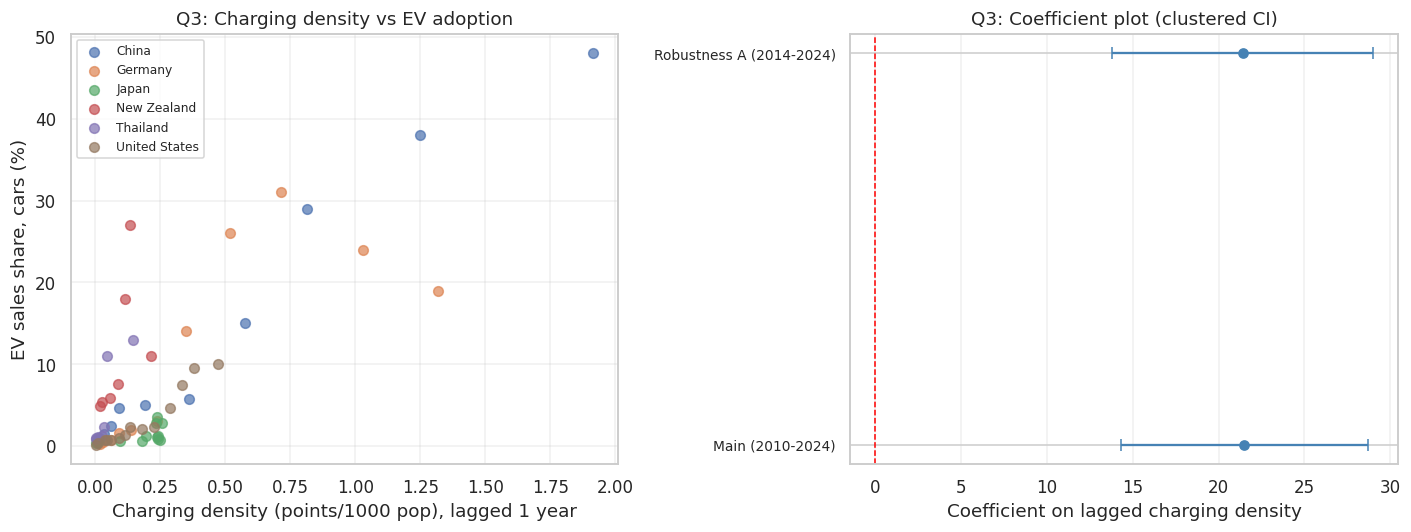

In [18]:
# --- Q3 plots ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: charging density (lagged) vs EV adoption, by country
ax = axes[0]
for country, sub in panel_lag.groupby("country"):
    ax.scatter(sub["lag_charging"], sub["ev_share"], label=country, s=40, alpha=0.7)
ax.set_xlabel("Charging density (points/1000 pop), lagged 1 year")
ax.set_ylabel("EV sales share, cars (%)")
ax.set_title("Q3: Charging density vs EV adoption")
ax.legend(fontsize=8, loc="upper left")
ax.grid(True, alpha=0.3)

# Plot 2: coefficient plot (main + robustness)
ax = axes[1]
specs = ["Main (2010-2024)", "Robustness A (2014-2024)"]
coefs = [res_main.params["lag_charging"], res_14.params["lag_charging"]]
cis = [res_main.conf_int().loc["lag_charging"].values,
       res_14.conf_int().loc["lag_charging"].values]
y_pos = np.arange(len(specs))
ax.errorbar(coefs, y_pos, xerr=[(c[1]-c[0])/2 for c in cis],
            fmt="o", capsize=4, color="steelblue")
ax.axvline(0, color="red", linestyle="--", lw=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(specs, fontsize=9)
ax.set_xlabel("Coefficient on lagged charging density")
ax.set_title("Q3: Coefficient plot (clustered CI)")
ax.grid(True, axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


In [19]:
# --- Q3 Interpretation ---
print("=== Q3 — Explicit answer ===")
print(f"Panel: 6 countries, {res_main.nobs} country-year observations (after 1-year lag).")
print(f"Lag (main model): coef = {res_main.params['lag_charging']:.4f}, "
      f"clustered p = {res_main.pvalues['lag_charging']:.4f}")
print(f"Wild cluster bootstrap 95% CI: [{ci_boot[0]:.4f}, {ci_boot[1]:.4f}]")
print(f"Lead (diagnostic): coef = {res_lead.params['lead_charging']:.4f}, "
      f"p = {res_lead.pvalues['lead_charging']:.4f}, significant = {lead_sig}")
print()
print(f"Verdict: {verdict}")
print()
print("Limitations: 6 clusters (low power), unbalanced panel, charging density")
print("from IEA (coverage varies by country). Vietnam excluded (only 2 years).")
print("Q3b (US tax-credit event study) deferred to future work (ADR-006 D.7).")


=== Q3 — Explicit answer ===
Panel: 6 countries, 64 country-year observations (after 1-year lag).
Lag (main model): coef = 21.5129, clustered p = 0.0000
Wild cluster bootstrap 95% CI: [15.2544, 27.7714]
Lead (diagnostic): coef = 13.0513, p = 0.0001, significant = True

Verdict: Không xác định — thiết kế không tách được chiều (lead có ý nghĩa)

Limitations: 6 clusters (low power), unbalanced panel, charging density
from IEA (coverage varies by country). Vietnam excluded (only 2 years).
Q3b (US tax-credit event study) deferred to future work (ADR-006 D.7).


## Q3b — US tax-credit event study (future work)

Placeholder. Hoãn sang future work (ADR-006 D.7).

In [20]:
# Q3b placeholder

## Q4 — Vietnam two-wheeler transition (Khoi)

### Preprocessing (`2 and 3 wheelers`, transport share)

### Analysis (descriptive, avoided-CO2 band)

### Results

### Interpretation

In [21]:
# Q4 code here